In [1]:
##################
### Keagan Moo ###
### 2024/08/15 ###
### RNA OComp  ###
##################

# This script loads in the significant hits from the Nature Aging April 2024 paper and our results for a comparison of overlap in the lists
# including directional information.
suppressPackageStartupMessages(library(ggplot2))
suppressPackageStartupMessages(library(data.table))
suppressPackageStartupMessages(library(glue))
suppressPackageStartupMessages(library(dplyr))

In [2]:
# Load in our data and results and filter for FDR < 0.1
Type1MAST <- read.csv(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_1_MAST_Total_GoExNom.csv")
Type1MASTsig <- Type1MAST[Type1MAST$fdr < 0.05,]
Type2aMAST <- read.csv(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_2a_MAST_Total_GoExNom.csv")
Type2aMASTsig <- Type2aMAST[Type2aMAST$fdr < 0.05,]
Type2xMAST <- read.csv(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_2x_MAST_Total_GoExNom.csv")
Type2xMASTsig <- Type2xMAST[Type2xMAST$fdr < 0.05,]

In [16]:
head(Type1MAST)
min(Type1MAST[!is.na(Type1MAST$fdr),]$fdr)
dim(Type1MASTsig)
dim(Type1MASTsig)
head(Type1MASTsig)
Type1MASTsig[Type1MASTsig$coef < 0, ]

,X,primerid,Symbol,Pr..Chisq.,coef,fdr
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,1,ENSG00000000419.12,DPM1,0.13033896,8.230897e-04,0.4807337
2,2,ENSG00000000457.14,SCYL3,0.02371257,8.393350e-04,0.2176403
3,3,ENSG00000000460.17,C1orf112,0.27956005,-9.969801e-05,0.6339780
4,4,ENSG00000001084.12,GCLC,0.22941880,3.665421e-04,0.5850268
5,5,ENSG00000001497.16,LAS1L,0.41005526,7.743366e-04,0.7336971
6,6,ENSG00000001629.10,ANKIB1,0.17535879,5.144672e-05,0.5317066


[1] 1.400355e-08

NULL

NULL

[1] "ENSG00000003989.17" "ENSG00000008311.15" "ENSG00000012232.8" 
[4] "ENSG00000020426.11" "ENSG00000047579.19" "ENSG00000048052.21"

ERROR: Error in Type1MASTsig$coef: $ operator is invalid for atomic vectors


In [3]:
Type1MASTsigVec <- unique(Type1MASTsig$primerid)
Type1MASTsigDWVec <- unique(Type1MASTsig[Type1MASTsig$coef < 0, ]$primerid)
Type2aMASTsigVec <- unique(Type2aMASTsig$primerid)
Type2aMASTsigDWVec <- unique(Type2aMASTsig[Type1MASTsig$coef < 0, ]$primerid)
Type2xMASTsigVec <- unique(Type2xMASTsig$primerid)
Type2xMASTsigDWVec <- unique(Type2xMASTsig[Type1MASTsig$coef < 0, ]$primerid)

In [21]:
length(Type1MASTsigVec)
length(Type1MASTsigDWVec)

[1] 346

[1] 156

In [4]:
# Load in outside paper list, only includes significant peaks, though statistical tests are radically different
TotalLTSR <- read.csv(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/externalFiles/NatureAging_DEG.csv")
Type1LTSR <-TotalLTSR[TotalLTSR$celltype %in% c("MF-I", "MF-Isn(fg)"),]
Type1LTSRVec <- unique(TotalLTSR[TotalLTSR$celltype %in% c("MF-I", "MF-Isn(fg)"),]$SYMBOL)
Type1LTSRDWVec <- unique(TotalLTSR[(TotalLTSR$celltype %in% c("MF-I", "MF-Isn(fg)")) & (TotalLTSR$REGULATION == "DW"),]$SYMBOL)

Type2LTSR <-TotalLTSR[TotalLTSR$celltype %in% c("MF-II", "MF-IIsn(fg)"),]
Type2LTSRVec <- unique(TotalLTSR[TotalLTSR$celltype %in% c("MF-II", "MF-IIsn(fg)"),]$SYMBOL)
Type2LTSRDWVec <- unique(TotalLTSR[(TotalLTSR$celltype %in% c("MF-II", "MF-IIsn(fg)")) & (TotalLTSR$REGULATION == "DW"),]$SYMBOL)

,celltype,SYMBOL,ENSEMBL,ltsr,beta_old,beta_young,prop_young,prop_old,n_cells_young,n_cells_old,log2fc,REGULATION
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<chr>
27,MF-I,RERE,ENSG00000142599,1.0000000,-0.21237144,0.26054233,0.7731343,0.62200381,22110,19942,-0.47291377,DW
28,MF-I,SLC2A5,ENSG00000142583,0.9720443,0.05447013,-0.04397388,0.0605156,0.13303580,22110,19942,0.09844401,UP
29,MF-I,ARHGEF10L,ENSG00000074964,0.9968775,-0.07854091,0.08783007,0.2158752,0.11914552,22110,19942,-0.16637098,DW
30,MF-I,MYOM3,ENSG00000142661,1.0000000,-0.28112092,0.34849864,0.6146992,0.32037910,22110,19942,-0.62961955,DW
31,MF-I,STX12,ENSG00000117758,1.0000000,-0.13212443,0.12794198,0.2325645,0.09241801,22110,19942,-0.26006641,DW
32,MF-I,AL139260.1,ENSG00000228436,1.0000000,-0.09593081,0.11080880,0.1999548,0.09377194,22110,19942,-0.20673961,DW


[1] 666

[1] 393

[1] "RERE"         "SLC2A5"       "ARHGEF10L"    "MYOM3"        "STX12"       
  [6] "AL139260.1"   "MKNK1"        "EPS15"        "OSBPL9"       "ACOT11"      
 [11] "DHCR24"       "PRKAA2"       "JUN"          "NFIA"         "NEXN-AS1"    
 [16] "CYR61"        "FNBP1L"       "PALMD"        "AGL"          "LRRC39"      
 [21] "SYPL2"        "DENND2C"      "AMPD1"        "CSDE1"        "CASQ2"       
 [26] "ATP1A1"       "TBX15"        "RNF115"       "TXNIP"        "NBPF14"      
 [31] "AC245297.3"   "NBPF19"       "TPM3"         "ATP1A2"       "CASQ1"       
 [36] "PBX1"         "UCK2"         "DUSP27"       "POU2F1"       "PRRX1"       
 [41] "PRDX6"        "RASAL2"       "QSOX1"        "IER5"         "IGFN1"       
 [46] "TNNI1"        "PLXNA2"       "ATF3"         "PTPN14"       "ESRRG"       
 [51] "TGFB2"        "DUSP10"       "TP53BP2"      "AC099066.2"   "TAF5L"       
 [56] "C1orf198"     "EGLN1"        "CNST"         "GREB1"        "LPIN1"       
 [61] "LAPTM4A"      "ITSN2"        "NCOA1"        "HADHA"        "HADHB"       
 [66] "FOSL2"        "TOGARAM2"     "LINC00486"    "FEZ2"         "PPM1B"       
 [71] "PRKCE"        "RTN4"         "WDPCP"        "MDH1"         "UGP2"        
 [76] "RETSAT"       "TBC1D8"       "TMEM182"      "SH3RF3"       "NPHP1"       
 [81] "BIN1"         "NEB"          "ARL5A"        "TANC1"        "XIRP2"       
 [86] "CERS6"        "KLHL41"       "FASTKD1"      "SLC25A12"     "MAP3K20"     
 [91] "OSBPL6"       "TTN"          "ZNF385B"      "ITGAV"        "ANKRD44"     
 [96] "SPATS2L"      "CFLAR"        "BARD1"        "TNS1"         "CYP27A1"     
[101] "PRKAG3"       "SPEG"         "DOCK10"       "HDAC4"        "SUMF1"       
[106] "BHLHE40"      "LMCD1-AS1"    "LMCD1"        "SETD5"        "GRIP2"       
[111] "ANKRD28"      "TBC1D5"       "ZNF385D"      "UBE2E2"       "THRB"        
[116] "SLC4A7"       "ARPP21"       "XIRP1"        "KLHL40"       "LRRC2"       
[121] "ARIH2"        "CACNA2D3"     "SLMAP"        "FHIT"         "ARL6IP5"     
[126] "GBE1"         "CADM2"        "CRYBG3"       "TBC1D23"      "NAA50"       
[131] "ATP2C1"       "NEK11"        "PPP2R3A"      "SLC25A36"     "PXYLP1"      
[136] "ZBTB38"       "ZIC1"         "WWTR1"        "CCNL1"        "PPM1L"       
[141] "TBL1XR1"      "USP13"        "ATP11B"       "RUBCN"        "AC093607.1"  
[146] "PPARGC1A"     "RBPJ"         "TBC1D1"       "GPAT3"        "MAPK10"      
[151] "PDLIM5"       "BMPR1B"       "EIF4E"        "C4orf54"      "HADH"        
[156] "EGF"          "ANK2"         "AC108866.1"   "LINC01091"    "INPP4B"      
[161] "AC139720.1"   "AC104596.1"   "FAM160A1"     "ASB5"         "ACSL1"       
[166] "ANKRD37"      "RETREG1"      "PDZD2"        "SLC1A3"       "LIFR"        
[171] "RICTOR"       "GHR"          "NNT-AS1"      "NNT"          "ARL15"       
[176] "PDE4D"        "MAST4"        "SERINC5"      "CKMT2-AS1"    "CKMT2"       
[181] "SSBP2"        "TMEM161B-AS1" "MEF2C-AS1"    "LUCAT1"       "PAM"         
[186] "ZNF608"       "SLC22A4"      "SLC22A5"      "AC116366.3"   "HSPA4"       
[191] "EGR1"         "HBEGF"        "NR3C1"        "CSNK1A1"      "SLC36A2"     
[196] "SGCD"         "COL23A1"      "SERPINB6"     "SLC22A23"     "JARID2"      
[201] "RBM24"        "CAP2"         "E2F3"         "RIPOR2"       "HSPA1A"      
[206] "HSPA1B"       "FKBP5"        "VEGFA"        "CLIC5"        "RCAN2"       
[211] "FOXO3"        "REV3L"        "NKAIN2"       "TPD52L1"      "HDDC2"       
[216] "EYA4"         "PDE7B"        "MAP3K5"       "SYNE1"        "TIAM2"       
[221] "SYNJ2"        "PRKN"         "RPS6KA2"      "ACTB"         "AC011287.1"  
[226] "HDAC9"        "DNAH11"       "CREB5"        "CPVL"         "AUTS2"       
[231] "POR"          "HSPB1"        "MAGI2"        "CD36"         "CDK14"       
[236] "PDK4"         "NAMPT"        "DOCK4"        "IFRD1"        "CPED1"       
[241] "ASB15"        "LMOD2"        "HYAL4"        "CALU"         "FLNC"        
[246] "FLNC-AS1"     "KCP"       

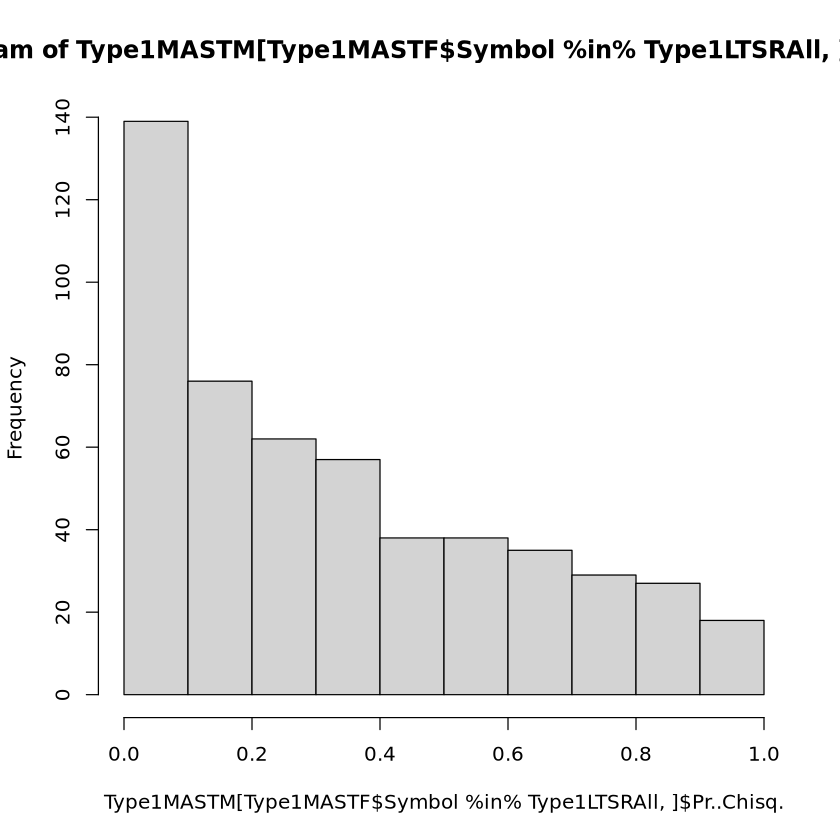

In [7]:
head(Type1LTSR)

length(Type1LTSRAll)
length(Type1LTSRDW)

Type1LTSRAll

hist(Type1MASTM[Type1MASTF$Symbol %in% Type1LTSRAll,]$Pr..Chisq.)

In [3]:
# Load in outside Dan's paper
TotalDan <- read.table(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/externalFiles/TableS4.1.tab", sep = "\t", header = TRUE)


In [51]:
Type1Dan <- TotalDan %>% filter(Cell.type == "Type 1", Trait.of.interest == "AGE", is.na(X2nd.trait.adjusted.for))
row.names(Type1Dan) <- NULL
write.table(Type1Dan, file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/externalFiles/Dan_Type1Age.tsv", sep = "\t")
Type2aDan <- TotalDan %>% filter(Cell.type == "Type 2a", Trait.of.interest == "AGE", is.na(X2nd.trait.adjusted.for))
row.names(Type2aDan) <- NULL
write.table(Type2aDan, file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/externalFiles/Dan_Type2aAge.tsv", sep = "\t")
Type2xDan <- TotalDan %>% filter(Cell.type == "Type 2x", Trait.of.interest == "AGE", is.na(X2nd.trait.adjusted.for))
row.names(Type2xDan) <- NULL
write.table(Type2xDan, file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/externalFiles/Dan_Type2xAge.tsv", sep = "\t")

In [24]:
Type1Dan <- read.table(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/externalFiles/Dan_Type1Age.tsv", sep = "\t")
Type1DanAll <- unique(Type1Dan$Gene)
Type1DanDW <- unique(Type1Dan[Type1Dan$Log2.Fold.Change < 0,]$Gene)

In [54]:
head(Type1Dan)
head(Type1MAST)
#merge(Type1MAST, Type1Dan, by.x= "primerid", by.y = "Gene")

,Gene,Mean.gene.count,Log2.Fold.Change,Log2.Fold.Change.Standard.error,Statistic,P.value,FDR,Cell.type,Trait.of.interest,X2nd.trait.adjusted.for,Sample.size
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>
1,ENSG00000250978.5,75.393405,0.37906598,0.05893680,35.28297,2.851140e-09,6.799684e-05,Type 1,AGE,NA,263
2,ENSG00000080986.13,3.673115,0.59935602,0.10635281,32.20379,1.388197e-08,1.655356e-04,Type 1,AGE,NA,263
3,ENSG00000152217.18,1109.015183,-0.07844329,0.01475653,28.44902,9.619821e-08,7.647437e-04,Type 1,AGE,NA,263
4,ENSG00000166444.19,55.053848,-0.14502736,0.02812840,27.57837,1.508562e-07,8.994423e-04,Type 1,AGE,NA,263
5,ENSG00000172995.16,1277.675108,0.12239349,0.02369292,26.13957,3.176087e-07,1.514930e-03,Type 1,AGE,NA,263
6,ENSG00000227954.6,39.572084,-0.24463994,0.04821870,25.25014,5.035585e-07,2.001561e-03,Type 1,AGE,NA,263


,X,primerid,Symbol,Pr..Chisq.,coef,fdr
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,1,ENSG00000000419.12,DPM1,0.13033896,8.230897e-04,0.4807337
2,2,ENSG00000000457.14,SCYL3,0.02371257,8.393350e-04,0.2176403
3,3,ENSG00000000460.17,C1orf112,0.27956005,-9.969801e-05,0.6339780
4,4,ENSG00000001084.12,GCLC,0.22941880,3.665421e-04,0.5850268
5,5,ENSG00000001497.16,LAS1L,0.41005526,7.743366e-04,0.7336971
6,6,ENSG00000001629.10,ANKIB1,0.17535879,5.144672e-05,0.5317066


In [61]:
batchCompDatF <- merge(Type1MAST, Type1Dan, by.x= "primerid", by.y = "Gene") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, P.value, Log2.Fold.Change, FDR)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF$modp.y <- -log10(batchCompDatF$P.value)*sign(batchCompDatF$Log2.Fold.Change)
#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
if (nrow(batchCompDatF[(is.na(batchCompDatF$FDR)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$FDR)),]$FDR <- 1
}

#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.1,]$ColorBlock <- "FDR < 0.1 in Moo et al"
batchCompDatF[batchCompDatF$FDR < 0.1,]$ColorBlock <- "FDR < 0.1 in Ciotlos et al"
batchCompDatF[(batchCompDatF$FDR < 0.1) & (batchCompDatF$fdr < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
ourLine <- lm(batchCompDatF$modp.y~batchCompDatF$modp.x-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVDan_pvalCompare_Type_1_FRD01.pdf"), width=6, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=-log10(P.value)*sign(Log2.Fold.Change))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3)+#, position = position_jitter(width = 0.01)) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + xlim(-12,12) + ylim(-12,12) +
        xlab("Moo et al -log10(Nominal P-value)*sign(log2FC)") + ylab("Ciotlos -log10(Nominal P-value)*sign(log2FC)") + ggtitle(glue("Comparing Nominal P-values Between Methods")) 
   print(mygg)
dev.off()

batchCompDatF <- merge(Type2aMAST, Type2aDan, by.x= "primerid", by.y = "Gene") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, P.value, Log2.Fold.Change, FDR)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF$modp.y <- -log10(batchCompDatF$P.value)*sign(batchCompDatF$Log2.Fold.Change)
#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
if (nrow(batchCompDatF[(is.na(batchCompDatF$FDR)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$FDR)),]$FDR <- 1
}

#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.1,]$ColorBlock <- "FDR < 0.1 in Moo et al"
batchCompDatF[batchCompDatF$FDR < 0.1,]$ColorBlock <- "FDR < 0.1 in Ciotlos et al"
batchCompDatF[(batchCompDatF$FDR < 0.1) & (batchCompDatF$fdr < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
ourLine <- lm(batchCompDatF$modp.y~batchCompDatF$modp.x-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVDan_pvalCompare_Type_2a_FRD01.pdf"), width=6, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=-log10(P.value)*sign(Log2.Fold.Change))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3)+#, position = position_jitter(width = 0.01)) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + xlim(-12,12) + ylim(-12,12) +
        xlab("Moo et al -log10(Nominal P-value)*sign(log2FC)") + ylab("Ciotlos -log10(Nominal P-value)*sign(log2FC)") + ggtitle(glue("Comparing Nominal P-values Between Methods")) 
   print(mygg)
dev.off()

batchCompDatF <- merge(Type2xMAST, Type2xDan, by.x= "primerid", by.y = "Gene") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, P.value, Log2.Fold.Change, FDR)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF$modp.y <- -log10(batchCompDatF$P.value)*sign(batchCompDatF$Log2.Fold.Change)
#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
if (nrow(batchCompDatF[(is.na(batchCompDatF$FDR)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$FDR)),]$FDR <- 1
}

#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.1,]$ColorBlock <- "FDR < 0.1 in Moo et al"
batchCompDatF[batchCompDatF$FDR < 0.1,]$ColorBlock <- "FDR < 0.1 in Ciotlos et al"
batchCompDatF[(batchCompDatF$FDR < 0.1) & (batchCompDatF$fdr < 0.1),]$ColorBlock <- "FDR < 0.1 in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
ourLine <- lm(batchCompDatF$modp.y~batchCompDatF$modp.x-1)
summary(ourLine)$coefficients[1]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVDan_pvalCompare_Type_2x_FRD01.pdf"), width=6, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=-log10(P.value)*sign(Log2.Fold.Change))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3)+#, position = position_jitter(width = 0.01)) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        geom_abline(intercept = 0, slope = summary(ourLine)$coefficients[1], alpha = 1, col = "red")+
        theme_bw() + xlim(-12,12) + ylim(-12,12) +
        xlab("Moo et al -log10(Nominal P-value)*sign(log2FC)") + ylab("Ciotlos -log10(Nominal P-value)*sign(log2FC)") + ggtitle(glue("Comparing Nominal P-values Between Methods")) 
   print(mygg)
dev.off()

[1] 0.6820825

pdf 
  2

[1] 0.7076176

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

[1] 0.6350288

Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

In [14]:
head(Type1LTSR)
nrow(Type1MAST)
-log10(1.0000000001-1)

,celltype,SYMBOL,ENSEMBL,ltsr,beta_old,beta_young,prop_young,prop_old,n_cells_young,n_cells_old,log2fc,REGULATION
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<chr>
27,MF-I,RERE,ENSG00000142599,1.0000000,-0.21237144,0.26054233,0.7731343,0.62200381,22110,19942,-0.47291377,DW
28,MF-I,SLC2A5,ENSG00000142583,0.9720443,0.05447013,-0.04397388,0.0605156,0.13303580,22110,19942,0.09844401,UP
29,MF-I,ARHGEF10L,ENSG00000074964,0.9968775,-0.07854091,0.08783007,0.2158752,0.11914552,22110,19942,-0.16637098,DW
30,MF-I,MYOM3,ENSG00000142661,1.0000000,-0.28112092,0.34849864,0.6146992,0.32037910,22110,19942,-0.62961955,DW
31,MF-I,STX12,ENSG00000117758,1.0000000,-0.13212443,0.12794198,0.2325645,0.09241801,22110,19942,-0.26006641,DW
32,MF-I,AL139260.1,ENSG00000228436,1.0000000,-0.09593081,0.11080880,0.1999548,0.09377194,22110,19942,-0.20673961,DW


[1] 6575

[1] 10

[1] 531

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000152217.18,4.260283e-12,-0.04638477,1.400355e-08,-1,0.9118683,-11.370562,-1.054868,Significant in Both
2,ENSG00000175161.13,4.822955e-11,-0.05510734,1.056870e-07,-1,1.0000000,-10.316687,-Inf,Significant in Both
3,ENSG00000146809.13,7.578641e-11,-0.04340502,1.245550e-07,-1,0.9999951,-10.120409,-5.313096,Significant in Both
4,ENSG00000172995.16,4.106599e-10,0.01967450,3.856683e-07,-1,0.9999998,9.386518,-6.677781,Significant in Both
5,ENSG00000265142.8,2.206012e-07,-0.05620931,1.208527e-04,-1,1.0000000,-6.656392,-Inf,Significant in Both
6,ENSG00000171408.14,6.155883e-07,-0.02510679,2.129936e-04,-1,0.9999227,-6.210710,-4.111719,Significant in Both


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

[1] 108

...

[1] 0.1864407

[1] 419

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000160299.17,2.076873e-12,0.04085223,5.839127e-09,-1,0.9677279,11.682590,-1.491172,Significant in Both
2,ENSG00000175161.13,3.955728e-10,-0.04471150,3.177580e-07,-1,1.0000000,-9.402774,-7.657577,Significant in Both
3,ENSG00000065882.16,1.058076e-09,-0.06436687,6.610622e-07,-1,1.0000000,-8.975483,-Inf,Significant in Both
4,ENSG00000137766.17,4.650984e-09,0.01466421,1.868034e-06,-1,0.9999139,8.332455,-4.064916,Significant in Both
5,ENSG00000077157.22,6.049409e-09,-0.01637141,2.267722e-06,-1,1.0000000,-8.218287,-Inf,Significant in Both
6,ENSG00000146809.13,3.037038e-08,-0.04028243,7.762393e-06,-1,0.9852950,-7.517550,-1.832534,Significant in Both


Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

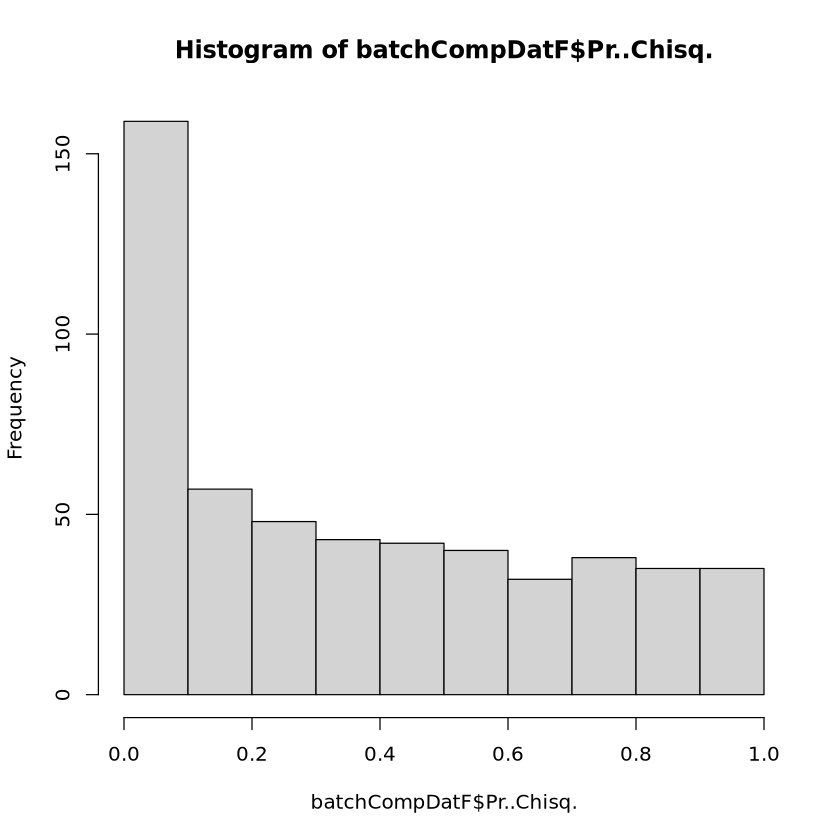

[1] 80

[1] 0.1909308

[1] 196

[1] 0.4677804

[1] 114

...

[1] 0.08353222

[1] 429

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000146809.13,3.528577e-10,-0.047430313,4.096678e-07,-1,0.9852950,-9.452400,-1.832534,Significant in Both
2,ENSG00000265142.8,7.818056e-09,-0.058189464,6.483402e-06,-1,1.0000000,-8.106901,-Inf,Significant in Both
3,ENSG00000137766.17,1.404481e-08,0.015439265,1.004814e-05,-1,0.9999139,7.852484,-4.064916,Significant in Both
4,ENSG00000154263.17,1.557850e-08,0.008458927,1.004814e-05,-1,0.9996701,7.807474,-3.481655,Significant in Both
5,ENSG00000077157.22,4.769208e-08,-0.024257232,2.516841e-05,-1,1.0000000,-7.321554,-Inf,Significant in Both
6,ENSG00000113916.18,7.813187e-08,0.053360532,3.239682e-05,-1,1.0000000,7.107172,-Inf,Significant in Both


Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

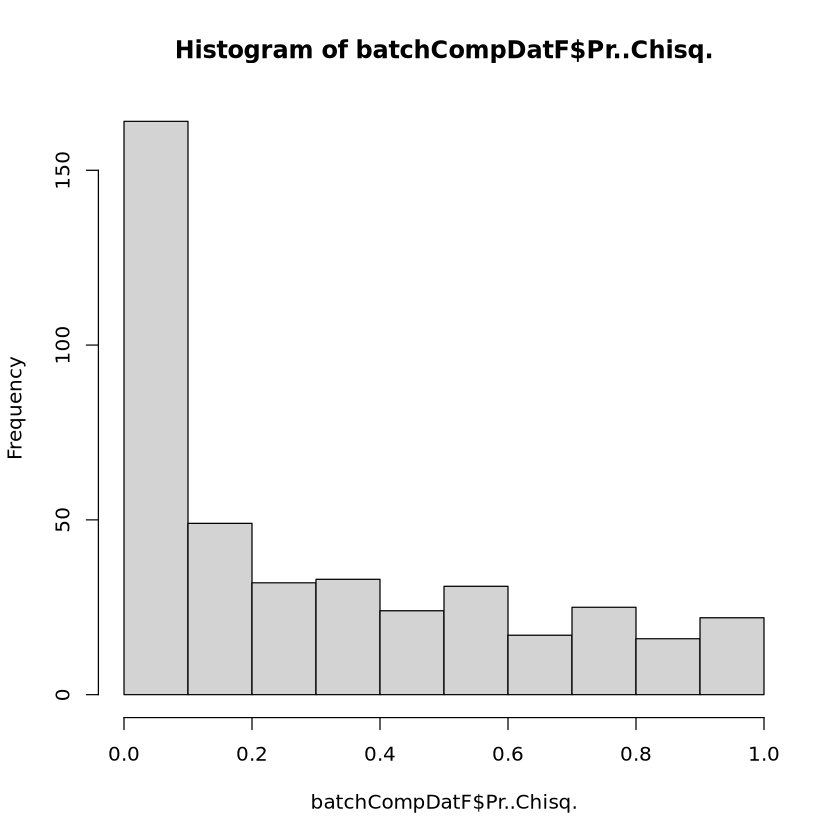

[1] 61

[1] 0.1421911

[1] 198

[1] 0.4615385

[1] 119

[1] 0.2773893

[1] 57

[1] 0.1328671

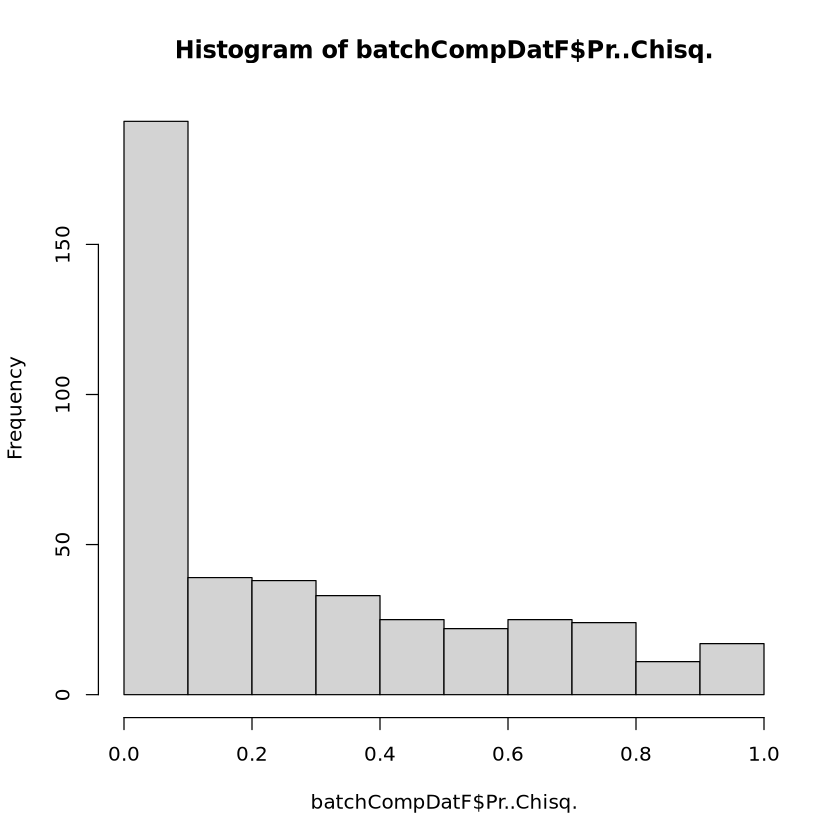

In [20]:
batchCompDatF <- merge(Type1MAST, Type1LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- -log10(1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION) 

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.05,]$ColorBlock <- "FDR < 0.05 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.05) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_1_FRD005_Original.pdf"), width=7, height=7)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=-log10(1.0000000001-ltsr)*sign(REGULATION))) + # Offset to place ltsr = 1 values in graphable space, at 10 specifically, as 9 appears to be where kedlian et al. started rounding the ltsr values up
        geom_point(aes(color = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-15,15) + ylim(-10.5,10.5) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()
#batchCompDatF <- batchCompDatF[!(is.infinite(batchCompDatF$modp.y)),]
#head(batchCompDatF)
#cor.test(batchCompDatF$modp.x, batchCompDatF$modp.y, method = "spearman")
#cor.test(batchCompDatF$fdr*sign(batchCompDatF$coef), (1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION), method = "spearman")
#cor.test(batchCompDatF$fdr, (1-batchCompDatF$ltsr), method = "spearman")
hist(batchCompDatF$Pr..Chisq.)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)

batchCompDatF <- merge(Type2aMAST, Type2LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- -log10(1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.05,]$ColorBlock <- "FDR < 0.05 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.05) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_2a_FRD005_Original.pdf"), width=7, height=7)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=-log10(1.0000000001-ltsr)*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-15,15) + ylim(-10.5,10.5) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()
#batchCompDatF <- batchCompDatF[!(is.infinite(batchCompDatF$modp.y)),]
#head(batchCompDatF)
#cor.test(batchCompDatF$modp.x, batchCompDatF$modp.y, method = "spearman")
#cor.test(batchCompDatF$fdr*sign(batchCompDatF$coef), (1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION), method = "spearman")
#cor.test(batchCompDatF$fdr, (1-batchCompDatF$ltsr), method = "spearman")
hist(batchCompDatF$Pr..Chisq.)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)

batchCompDatF <- merge(Type2xMAST, Type2LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- -log10(1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.05,]$ColorBlock <- "FDR < 0.05 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.05) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_2x_FRD005_Original.pdf"), width=7, height=7)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=-log10(1.0000000001-ltsr)*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-15,15) + ylim(-10.5,10.5) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()
#batchCompDatF <- batchCompDatF[!(is.infinite(batchCompDatF$modp.y)),]
#head(batchCompDatF)
#cor.test(batchCompDatF$modp.x, batchCompDatF$modp.y, method = "spearman")
#cor.test(batchCompDatF$fdr*sign(batchCompDatF$coef), (1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION), method = "spearman")
#cor.test(batchCompDatF$fdr, (1-batchCompDatF$ltsr), method = "spearman")
hist(batchCompDatF$Pr..Chisq.)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)

In [5]:
head(Type1LTSR)

,celltype,SYMBOL,ENSEMBL,ltsr,beta_old,beta_young,prop_young,prop_old,n_cells_young,n_cells_old,log2fc,REGULATION
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<chr>
27,MF-I,RERE,ENSG00000142599,1.0000000,-0.21237144,0.26054233,0.7731343,0.62200381,22110,19942,-0.47291377,DW
28,MF-I,SLC2A5,ENSG00000142583,0.9720443,0.05447013,-0.04397388,0.0605156,0.13303580,22110,19942,0.09844401,UP
29,MF-I,ARHGEF10L,ENSG00000074964,0.9968775,-0.07854091,0.08783007,0.2158752,0.11914552,22110,19942,-0.16637098,DW
30,MF-I,MYOM3,ENSG00000142661,1.0000000,-0.28112092,0.34849864,0.6146992,0.32037910,22110,19942,-0.62961955,DW
31,MF-I,STX12,ENSG00000117758,1.0000000,-0.13212443,0.12794198,0.2325645,0.09241801,22110,19942,-0.26006641,DW
32,MF-I,AL139260.1,ENSG00000228436,1.0000000,-0.09593081,0.11080880,0.1999548,0.09377194,22110,19942,-0.20673961,DW


In [21]:
batchCompDatF <- merge(Type1MAST, Type1LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- batchCompDatF$ltsr*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.1,]$ColorBlock <- "FDR < 0.1 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.1) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_1_FRD01_Steve.pdf"), width=8, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=(ltsr)*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=18)) + xlim(-15,15) + ylim(-1,1) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("Kedlian et al ltsr*sign(REGULATION)") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()

batchCompDatF <- merge(Type2aMAST, Type2LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- batchCompDatF$ltsr*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.1,]$ColorBlock <- "FDR < 0.1 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.1) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_2a_FRD01_Steve.pdf"), width=8, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=ltsr*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=18)) + xlim(-15,15) + ylim(-1,1) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("Kedlian et al ltsr*sign(REGULATION)") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()

batchCompDatF <- merge(Type2xMAST, Type2LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- -log10(1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.1,]$ColorBlock <- "FDR < 0.1 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.1) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_2x_FRD01_Steve.pdf"), width=8, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=ltsr*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=18)) + theme(text=element_text(size=18)) + xlim(-15,15) + ylim(-1,1) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("Kedlian et al ltsr*sign(REGULATION)") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()


[1] 531

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000152217.18,4.260283e-12,-0.04638477,1.400355e-08,-1,0.9118683,-11.370562,-0.9118683,Significant in Both
2,ENSG00000175161.13,4.822955e-11,-0.05510734,1.056870e-07,-1,1.0000000,-10.316687,-1.0000000,Significant in Both
3,ENSG00000146809.13,7.578641e-11,-0.04340502,1.245550e-07,-1,0.9999951,-10.120409,-0.9999951,Significant in Both
4,ENSG00000172995.16,4.106599e-10,0.01967450,3.856683e-07,-1,0.9999998,9.386518,-0.9999998,Significant in Both
5,ENSG00000265142.8,2.206012e-07,-0.05620931,1.208527e-04,-1,1.0000000,-6.656392,-1.0000000,Significant in Both
6,ENSG00000171408.14,6.155883e-07,-0.02510679,2.129936e-04,-1,0.9999227,-6.210710,-0.9999227,Significant in Both


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

[1] 419

...

pdf 
  2

[1] 429

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000146809.13,3.528577e-10,-0.047430313,4.096678e-07,-1,0.9852950,-9.452400,-1.832534,Significant in Both
2,ENSG00000265142.8,7.818056e-09,-0.058189464,6.483402e-06,-1,1.0000000,-8.106901,-Inf,Significant in Both
3,ENSG00000137766.17,1.404481e-08,0.015439265,1.004814e-05,-1,0.9999139,7.852484,-4.064916,Significant in Both
4,ENSG00000154263.17,1.557850e-08,0.008458927,1.004814e-05,-1,0.9996701,7.807474,-3.481655,Significant in Both
5,ENSG00000077157.22,4.769208e-08,-0.024257232,2.516841e-05,-1,1.0000000,-7.321554,-Inf,Significant in Both
6,ENSG00000113916.18,7.813187e-08,0.053360532,3.239682e-05,-1,1.0000000,7.107172,-Inf,Significant in Both


Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

In [9]:
length(intersect(Type1MASTsig, Type1DanAll))
length(intersect(Type1MASTsigDW, Type1DanDW))

intersect(Type1MASTsig, Type1DanAll)
#arrange(TotalLTSR[(TotalLTSR$SYMBOL %in% intersect(Type1MASTsig, Type1LTSRAll)) & (TotalLTSR$celltype %in% c("MF-I", "MF-Isn(fg)")),], SYMBOL)
#arrange(Type1MASTF[Type1MASTF$Symbol %in% intersect(Type1MASTsig, Type1LTSRAll),], Symbol)

#TOTO <- merge(TotalDan[(TotalDan$Gene %in% intersect(Type1MASTsig, Type1DanAll)) & (TotalDan$Cell.type %in% c("MF-I", "MF-Isn(fg)")),], Type1MASTM[Type1MASTF$Symbol %in% intersect(Type1MASTsig, Type1DanAll),], by.x = "SYMBOL", by.y = "Symbol")
#dim(TOTO)
#sum(sign(TOTO$log2fc) * sign(TOTO$coef) == 1)

[1] 24

[1] 13

[1] "ENSG00000047579.19" "ENSG00000065675.14" "ENSG00000066629.17"
 [4] "ENSG00000108671.11" "ENSG00000136848.17" "ENSG00000138768.14"
 [7] "ENSG00000143382.14" "ENSG00000146809.13" "ENSG00000151322.18"
[10] "ENSG00000152217.18" "ENSG00000153814.13" "ENSG00000158683.8" 
[13] "ENSG00000163378.14" "ENSG00000166444.19" "ENSG00000172995.16"
[16] "ENSG00000175161.13" "ENSG00000227954.6"  "ENSG00000250978.5" 
[19] NA                   "ENSG00000283662.1"  "ENSG00000131370.16"
[22] "ENSG00000160299.17" "ENSG00000164506.14" "ENSG00000185046.18"

In [28]:
(sign(TOTO$log2fc) * sign(TOTO$coef))

[1]  1 -1  1  1 -1  1  1  1  1  1  1 -1  1  1  1  1 -1 -1 -1 -1  1  1  1  1  1
[26]  1  1  1 -1  1  1  1  1 -1  1  1  1 -1  1  1  1  1

In [10]:
# Drawn Black = LSTR sig overlap with MAST sig
# Black = MAST sig
# White = nrow(MAST) - MAST sig
# Drawn = LSTR sig

phyper(24, 218, 13885 - 218, 63, lower.tail = TRUE, log.p = FALSE)

phyper(13, 123, 13885 - 123, 30, lower.tail = TRUE, log.p = FALSE)

[1] 1

[1] 1